# 3D Printing Failure Detection
### By Johnny Bray and Chang Rui liu

In [11]:
%pip install pillow
#import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, log_loss




Note: you may need to restart the kernel to use updated packages.


In [2]:
# import image processing
# this is the code to convert images to grayscale and save them as jpg files

'''from PIL import Image
from pathlib import Path

input_folder = Path("Cracking")
output_folder = Path("Cracking_grayscale_jpg") / "Cracking"
output_folder.mkdir(parents=True, exist_ok=True)

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
converted_count = 0

for file in input_folder.rglob("*"):
    if file.is_file() and file.suffix.lower() in image_extensions:
        image = Image.open(file).convert("L")
        output_file = output_folder / f"{file.stem}.jpg"
        image.save(output_file, "JPEG")
        converted_count += 1

print(f"Converted {converted_count} images.")
print(f"Saved to: {output_folder.resolve()}")
'''


'from PIL import Image\nfrom pathlib import Path\n\ninput_folder = Path("Cracking")\noutput_folder = Path("Cracking_grayscale_jpg") / "Cracking"\noutput_folder.mkdir(parents=True, exist_ok=True)\n\nimage_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}\nconverted_count = 0\n\nfor file in input_folder.rglob("*"):\n    if file.is_file() and file.suffix.lower() in image_extensions:\n        image = Image.open(file).convert("L")\n        output_file = output_folder / f"{file.stem}.jpg"\n        image.save(output_file, "JPEG")\n        converted_count += 1\n\nprint(f"Converted {converted_count} images.")\nprint(f"Saved to: {output_folder.resolve()}")\n'

In [3]:
# Import training, testing, and validation data that is presplit

from pathlib import Path
from PIL import Image
import numpy as np

dataset_root = Path("Gray Scale JPG")  # change if needed

CLASS_NAMES = [
    "Cracking",
    "Layer_shifting",
    "Off_platform",
    "Stringing",
    "Warping"
]

class_folders = [
    "Cracking_grayscale_jpg",
    "Layer_shifting_grayscale_jpg",
    "Off_platform_grayscale_jpg",
    "Stringing_grayscale_jpg",
    "Warping_grayscale_jpg"
]

IMG_SIZE = (128, 128)

def load_split(split_name):
    images, labels = [], []

    for label, folder_name in enumerate(class_folders):
        # Goes into: grayscale folder → class folder → requested split folder
        main_folder = dataset_root / folder_name
        class_folder = next(folder for folder in main_folder.iterdir() if folder.is_dir())

        split_folder = next(
            folder for folder in class_folder.iterdir()
            if folder.is_dir() and split_name.lower() in folder.name.lower()
        )

        image_files = (
            list(split_folder.glob("*.jpg")) +
            list(split_folder.glob("*.JPG")) +
            list(split_folder.glob("*.jpeg")) +
            list(split_folder.glob("*.JPEG"))
        )

        for image_path in image_files:
            image = Image.open(image_path).convert("L")
            image = image.resize(IMG_SIZE)

            images.append(np.array(image))
            labels.append(label)

    return np.array(images), np.array(labels)

X_train, y_train = load_split("training")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Classes:", CLASS_NAMES)

Training: (2738, 128, 128)
Validation: (582, 128, 128)
Testing: (576, 128, 128)
Classes: ['Cracking', 'Layer_shifting', 'Off_platform', 'Stringing', 'Warping']


### Simple Logistic Regression Model

In [4]:
# Convert each image into one long row of pixel values.
# Works whether images are shaped (N, H, W) or (N, H, W, 1).
X_train_lr = X_train.reshape(len(X_train), -1).astype("float32")
X_val_lr = X_val.reshape(len(X_val), -1).astype("float32")
X_test_lr = X_test.reshape(len(X_test), -1).astype("float32")

# Normalize pixel values only if they are currently 0–255.
if X_train_lr.max() > 1:
    X_train_lr /= 255.0
    X_val_lr /= 255.0
    X_test_lr /= 255.0

print("Training input shape:", X_train_lr.shape)
print("One image is represented by", X_train_lr.shape[1], "pixel features")

Training input shape: (2738, 16384)
One image is represented by 16384 pixel features


In [13]:
baseline_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    random_state=10
)

baseline_model.fit(X_train_lr, y_train)

# Predictions
train_predictions = baseline_model.predict(X_train_lr)
val_predictions = baseline_model.predict(X_val_lr)
test_predictions = baseline_model.predict(X_test_lr)

# Class probabilities are needed to calculate cross-entropy loss
train_probabilities = baseline_model.predict_proba(X_train_lr)
val_probabilities = baseline_model.predict_proba(X_val_lr)
test_probabilities = baseline_model.predict_proba(X_test_lr)

# Accuracy and loss for each dataset
results = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, train_predictions),
        accuracy_score(y_val, val_predictions),
        accuracy_score(y_test, test_predictions)
    ],
    "Cross-Entropy Loss": [
        log_loss(y_train, train_probabilities),
        log_loss(y_val, val_probabilities),
        log_loss(y_test, test_probabilities)
    ]
})

results["Accuracy"] = results["Accuracy"].map(lambda x: f"{x:.2%}")
results["Cross-Entropy Loss"] = results["Cross-Entropy Loss"].map(lambda x: f"{x:.4f}")

print(results)

      Dataset Accuracy Cross-Entropy Loss
0    Training  100.00%             0.0015
1  Validation   62.54%             1.9610
2     Testing   81.60%             1.2725


                precision    recall  f1-score   support

      Cracking       0.70      0.94      0.80       142
Layer_shifting       0.90      0.65      0.75       108
  Off_platform       1.00      0.07      0.13        28
     Stringing       0.95      0.79      0.86       134
       Warping       0.82      0.96      0.89       164

      accuracy                           0.82       576
     macro avg       0.87      0.68      0.69       576
  weighted avg       0.84      0.82      0.80       576



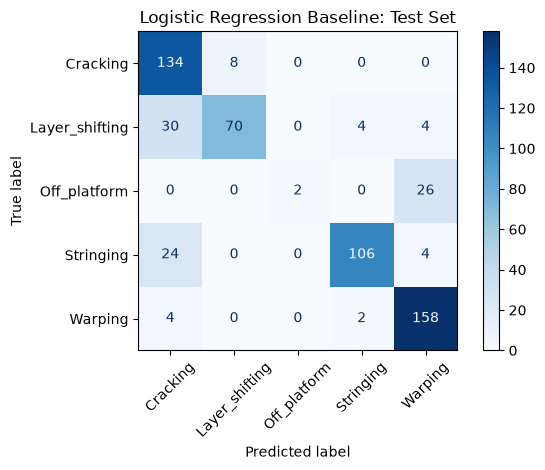

In [14]:
print(classification_report(
    y_test,
    test_predictions,
    target_names=CLASS_NAMES
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Logistic Regression Baseline: Test Set")
plt.tight_layout()
plt.show()

In [15]:
# Try several regularization strengths.
# Smaller C = stronger regularization
# Larger C = weaker regularization / can overfit more easily
C_values = [0.01, 0.1, 1, 10]

tuning_results = []
models = []

for C in C_values:
    model = LogisticRegression(
        C=C,
        max_iter=3000,
        solver="lbfgs",
        random_state=10
    )

    model.fit(X_train_lr, y_train)

    train_loss = log_loss(y_train, model.predict_proba(X_train_lr))
    val_loss = log_loss(y_val, model.predict_proba(X_val_lr))

    tuning_results.append({
        "C": C,
        "Training Accuracy": accuracy_score(y_train, model.predict(X_train_lr)),
        "Validation Accuracy": accuracy_score(y_val, model.predict(X_val_lr)),
        "Training Loss": train_loss,
        "Validation Loss": val_loss
    })

    models.append(model)

results_tuning = pd.DataFrame(tuning_results)
print(results_tuning)

best_index = results_tuning["Validation Loss"].idxmin()

best_C = results_tuning.loc[best_index, "C"]
baseline_model = models[best_index]

print(f"Best C value: {best_C}")
print(f"Lowest validation loss: {results_tuning.loc[best_index, 'Validation Loss']:.4f}")

test_predictions = baseline_model.predict(X_test_lr)
test_probabilities = baseline_model.predict_proba(X_test_lr)

print(f"Final test accuracy: {accuracy_score(y_test, test_predictions):.2%}")
print(f"Final test loss: {log_loss(y_test, test_probabilities):.4f}")

       C  Training Accuracy  Validation Accuracy  Training Loss  \
0   0.01           0.998539             0.560137       0.059701   
1   0.10           1.000000             0.611684       0.010375   
2   1.00           1.000000             0.625430       0.001454   
3  10.00           1.000000             0.618557       0.000495   

   Validation Loss  
0         1.307192  
1         1.518801  
2         1.960976  
3         3.446318  
Best C value: 0.01
Lowest validation loss: 1.3072
Final test accuracy: 80.56%
Final test loss: 0.7291


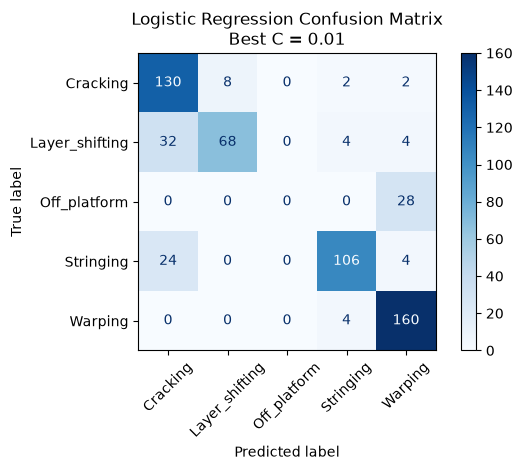

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title(f"Logistic Regression Confusion Matrix\nBest C = {best_C}")
plt.tight_layout()
plt.show()